# 基于 YOLO11 在自己标注的数据集上进行训练和验证

## 检查数据集中的边框

In [1]:
import os
import random
import pandas as pd
import seaborn as sns
import cv2
from ultralytics import YOLO
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [2]:
# 随机查看训练集中的图片及其标注信息
def load_image(image_path):
    """
    加载图片并将其以 BGR 格式转换为 RGB 格式

    参数：
    image_path: (str): 图片文件的路径

    返回：
    numpy.ndarray: RGB 格式的图片数组
    """
    image = cv2.imread(image_path) # 使用 OpenCV 读取图片
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB) # 将图片从 GBR 格式转换为 RGB 格式

In [6]:
def draw_bounding_boxes(image, label_path):
    """
    在图片上绘制边界框

    参数：
    image (numpy.ndarray): 输入的图片数组
    label_path (str): 对应的标签文件路径
    """
    with open(label_path, 'r') as file:
        lines = file.readlines() # 读取标签文件的所有行

    for line in lines:
        parts = line.strip().split() # 去除行末换行符并按空格分割
        class_id = int(parts[0]) # 第一个值是类别 ID
        x_center, y_center, width, height = map(float, parts[1:5]) # 后四个值分别是中心点坐标和宽高

        h, w, _ = image.shape # 获取图片的高度和宽度
        x_min = int((x_center - width / 2) * w) # 计算边界框左上角的 x 坐标
        y_min = int((y_center - height / 2) * h) # 计算边界框左上角的 y 坐标
        x_max = int((x_center + width / 2) * w) # 计算边界框右下角的 x 坐标
        y_max = int((y_center + height / 2) * h) # 计算边界框右下角的 y 坐标

        color = (random.randint(0, 255), random.randint(0, 255), random.randint(0, 255)) # 颜色随机
        cv2.rectangle(image, (x_min, y_min), (x_max, y_max), color, 3) # 绘制边界框，宽度为 3

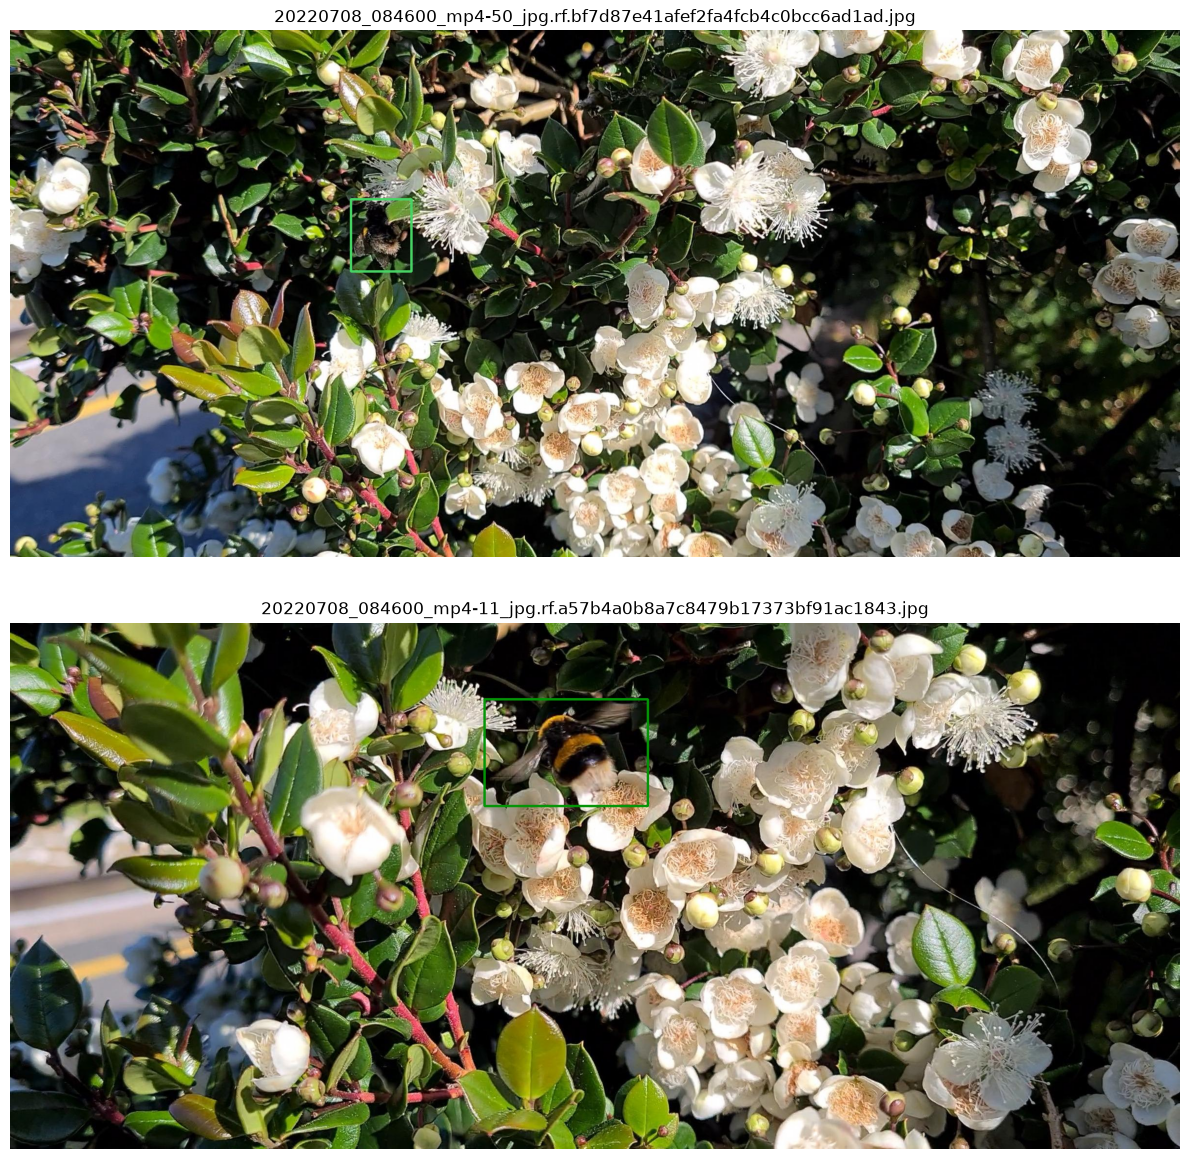

In [8]:
# 图片目录路径
images_dir = 'datasets/train/images'
# 标签目标路径
labels_dir = 'datasets/train/labels'
# 获取所有 .jpg 文件名
image_files = [f for f in os.listdir(images_dir) if f.endswith('.jpg')]
# 随机选择两张图片
selected_images = random.sample(image_files, 2)

# 创建两个子图，用于显示两张图片
fig, axes = plt.subplots(2, 1, figsize = (12, 12))

for ax, img_file in zip(axes, selected_images):
    img_path = os.path.join(images_dir, img_file) # 构建图片文件的完整路径
    label_file = img_file.replace('.jpg', '.txt') # 将文件扩展名替换为 .txt 以获得对应的标签文件
    label_path = os.path.join(labels_dir, label_file) # 构建标签文件的完整路径

    image = load_image(img_path) # 加载图片
    draw_bounding_boxes(image, label_path) # 在图片上绘制边界框

    ax.imshow(image) # 显示图片
    ax.axis('off') # 关闭坐标系
    ax.set_title(img_file) # 将子图标题设置为图片文件名

plt.tight_layout() # 自动调整子图参数，使之填充整个图片区域
plt.show() # 显示最终结果

## 模型训练

In [9]:
# 初始化一个 YOLO11 模型
model = YOLO('yolo11n.pt') # 使用预训练的 yolo11n.pt 模型
# 训练模型
results = model.train(
    data = 'data.yaml', # 数据集配置文件路径
    epochs = 10, # 训练轮数
    imgsz = 640, # 输入图片大小
    batch = 16, # 批处理大小
    device = 'cpu', # 设备选择，可以是 'cpu' 或 'cuda'
    save = True, # 保存训练结果
    plots = True # 保存训练和验证指标图以及预测实例
)

New https://pypi.org/project/ultralytics/8.4.211 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.208 🚀 Python-3.11.18 torch-2.15.0 CPU (Apple M1)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0

Kaggle 平台蜜蜂数据集: https://www.kaggle.com/datasets/lara311/bee-detection-dataset/data

In [11]:
os.listdir('kaggle/runs/detect/train')

['confusion_matrix.png',
 'val_batch1_labels.jpg',
 'args.yaml',
 'results.png',
 'BoxR_curve.png',
 'weights',
 'train_batch7062.jpg',
 'val_batch2_pred.jpg',
 'train_batch7060.jpg',
 'train_batch7061.jpg',
 'val_batch0_labels.jpg',
 'train_batch0.jpg',
 'train_batch1.jpg',
 'confusion_matrix_normalized.png',
 'train_batch2.jpg',
 'BoxF1_curve.png',
 'val_batch1_pred.jpg',
 'val_batch0_pred.jpg',
 'BoxP_curve.png',
 'labels.jpg',
 'results.csv',
 'val_batch2_labels.jpg',
 'BoxPR_curve.png']

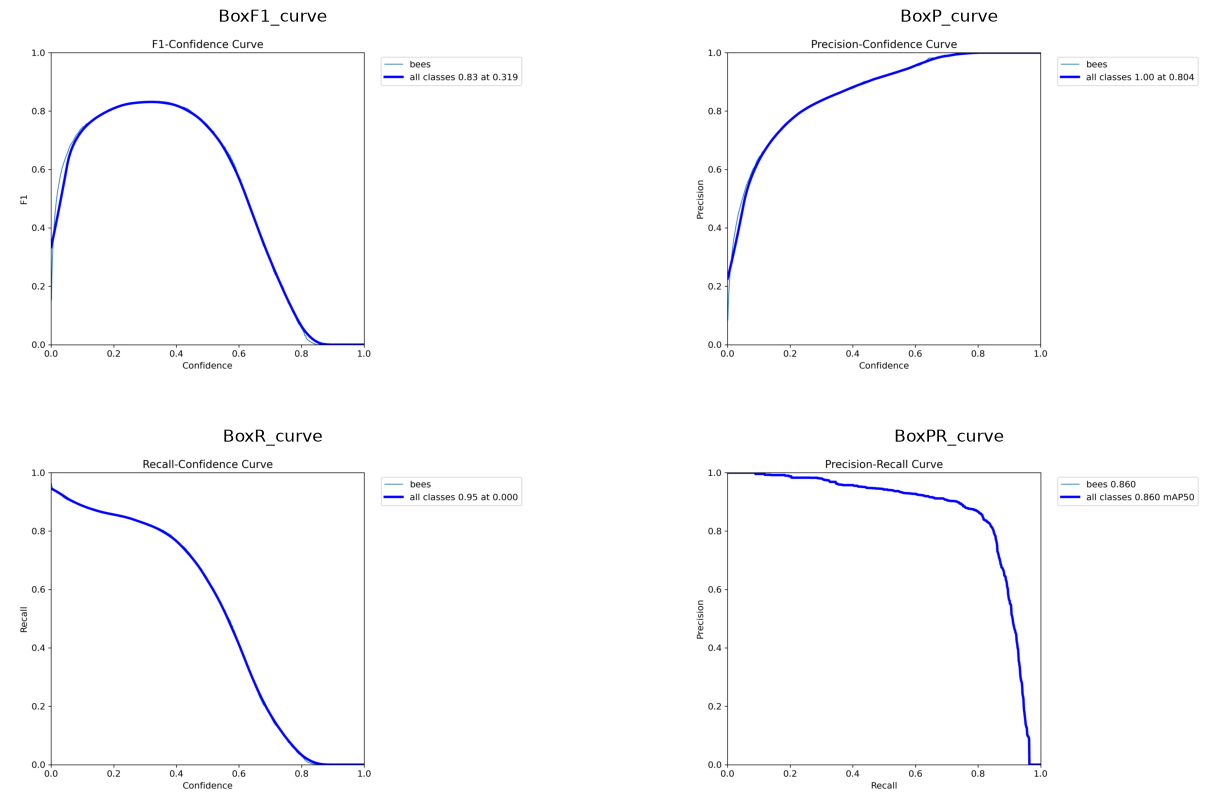

In [14]:
# 指定所在目录
directory = 'kaggle/runs/detect/train'

# 定义要展示的图片文件名
image_files = [
    'BoxF1_curve.png',
    'BoxP_curve.png',
    'BoxR_curve.png',
    'BoxPR_curve.png'
]

# 创建一张包含 4 张子图的图形
fig, axes = plt.subplots(2, 2, figsize = (16, 10))
axes = axes.flatten() # 将二维数组展平为一维数组以便于索引

# 遍历每个图片文件并加载到对应的子图中
for ax, image_file in zip(axes, image_files):
    image_path = os.path.join(directory, image_file)
    if os.path.exists(image_path):
        img = plt.imread(image_path)
        ax.imshow(img)
        ax.set_title(os.path.splitext(image_file)[0]) # 将子图标题设置为图片文件名（去掉扩展名）
        ax.axis('off') # 关闭坐标轴
    else:
        ax.text(0.5, 0.5, f"File not found: {image_file}", ha = 'center', va = 'center', fontsize = 12)
        ax.axis('off')

In [15]:
# 调整子图间距
plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

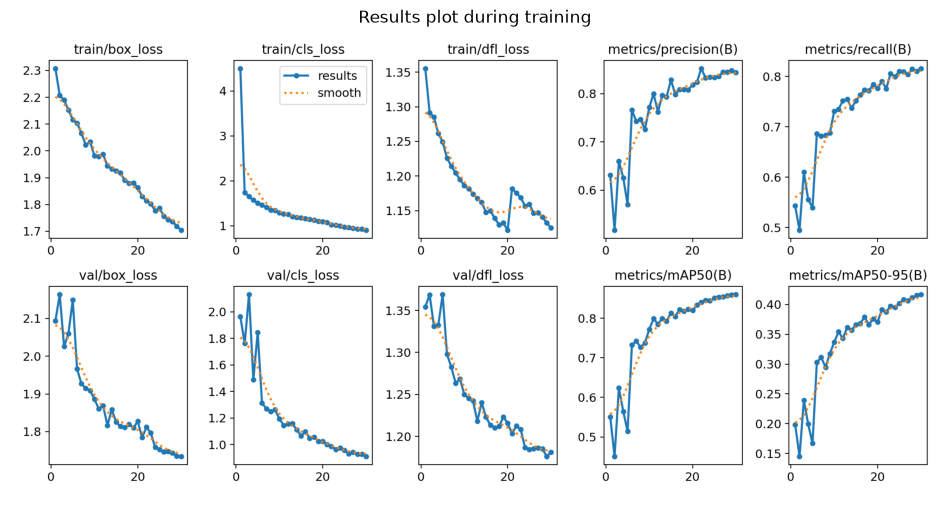

In [16]:
# 训练期间的指标变化

image_path = 'kaggle/runs/detect/train/results.png'
# 读取图片
img = plt.imread(image_path)
# 创建一个图形窗口并显示图片
plt.figure(figsize = (12, 8))
plt.imshow(img)
plt.title('Results plot during training')
plt.axis('off')
plt.show()

In [17]:
# results.csv
results = pd.read_csv('kaggle/runs/detect/train/results.csv')
results.tail()

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
25,26,2150.05,1.75647,0.96111,1.14664,0.83600,0.80974,0.85351,0.40817,1.74699,0.93199,1.18511,0.000350,0.000350,0.000350
26,27,2219.44,1.74267,0.94753,1.14697,0.84521,0.80364,0.85422,0.40624,1.74798,0.94156,1.18635,0.000284,0.000284,0.000284
27,28,2288.42,1.73654,0.93165,1.14089,0.84503,0.81487,0.85756,0.41164,1.74363,0.92726,1.18513,0.000218,0.000218,0.000218
28,29,2357.58,1.71929,0.92675,1.13242,0.84787,0.81026,0.85889,0.41525,1.73490,0.92639,1.17624,0.000152,0.000152,0.000152
29,30,2427.20,1.70392,0.90296,1.12505,0.84401,0.81590,0.86002,0.41675,1.73451,0.91106,1.18108,0.000086,0.000086,0.000086


## 模型验证

In [22]:
# 加载训练好的最优模型
model = YOLO('kaggle/runs/detect/train/weights/best.pt')
# 模型验证
metrics = model.val(data = 'kaggle/input/data.yaml')

Ultralytics 8.4.208 🚀 Python-3.11.18 torch-2.15.0 CPU (Apple M1)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2256.0±881.5 MB/s, size: 196.3 KB)
val: Scanning /Users/justin/Developer/ai-workspace/study-yolo11-in-action/chapter-6-data-annotation/bee-detections/kaggle/input/valid/labels... 1604 images, 237 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1604/1604 5.0Kit/s 0.3s0.0s
val: New cache created: /Users/justin/Developer/ai-workspace/study-yolo11-in-action/chapter-6-data-annotation/bee-detections/kaggle/input/valid/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 101/101 1.7it/s 58.3s0.6s
                   all       1604       1950      0.843      0.815      0.859      0.415
Speed: 0.3ms preprocess, 30.3ms inference, 0.0ms loss, 0.3ms postprocess per image
Results saved to /Users/justin/Developer/ai-workspace/study-yolo11-in-act

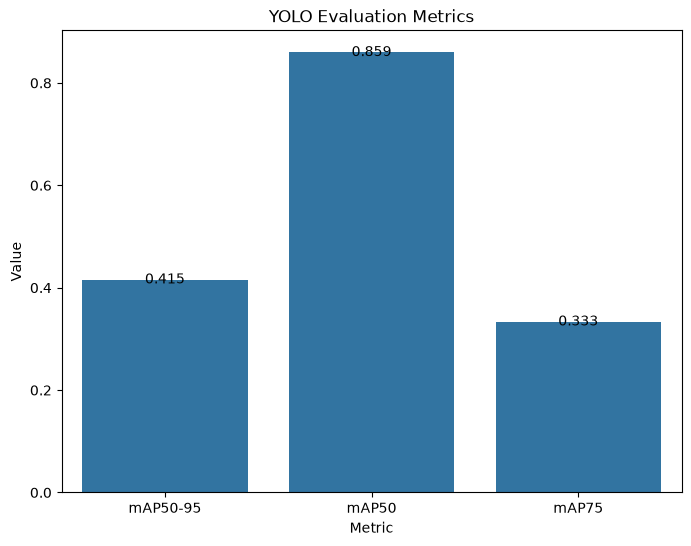

In [23]:
# 验证指标可视化

%matplotlib inline
# 创建柱状图
ax = sns.barplot(x = ['mAP50-95', 'mAP50', 'mAP75'], y = [metrics.box.map, metrics.box.map50, metrics.box.map75])

# 设置标题和轴标签
ax.set_title('YOLO Evaluation Metrics')
ax.set_xlabel('Metric')
ax.set_ylabel('Value')
fig = plt.gcf()
fig.set_size_inches(8, 6)
# 在柱状图上方添加数值
for p in ax.patches:
    ax.annotate("{:.3f}".format(p.get_height()), 
               (p.get_x() + p.get_width() / 2, p.get_height()),
                ha = 'center', va = 'center'
               )
# 显示图形
plt.show()

## 模型预测


image 1/1 /Users/justin/Developer/ai-workspace/study-yolo11-in-action/chapter-6-data-annotation/bee-detections/kaggle/input/test/images/lots-of-bees_mp4-1653_jpg.rf.5fc8a44470ea544d525696d27fce77cc.jpg: 384x640 2 beess, 43.0ms
Speed: 4.3ms preprocess, 43.0ms inference, 1.0ms postprocess per image at shape (1, 3, 384, 640)

image 1/1 /Users/justin/Developer/ai-workspace/study-yolo11-in-action/chapter-6-data-annotation/bee-detections/kaggle/input/test/images/bees-4_mp4-627_jpg.rf.929db151ce7d2e786bc923ab55ac2a77.jpg: 384x640 2 beess, 38.1ms
Speed: 1.0ms preprocess, 38.1ms inference, 0.4ms postprocess per image at shape (1, 3, 384, 640)

image 1/1 /Users/justin/Developer/ai-workspace/study-yolo11-in-action/chapter-6-data-annotation/bee-detections/kaggle/input/test/images/from-walk_mp4-1224_jpg.rf.9ce97a64d02c86133fe958a2ee23366a.jpg: 384x640 (no detections), 37.0ms
Speed: 0.9ms preprocess, 37.0ms inference, 0.2ms postprocess per image at shape (1, 3, 384, 640)

image 1/1 /Users/justin/De

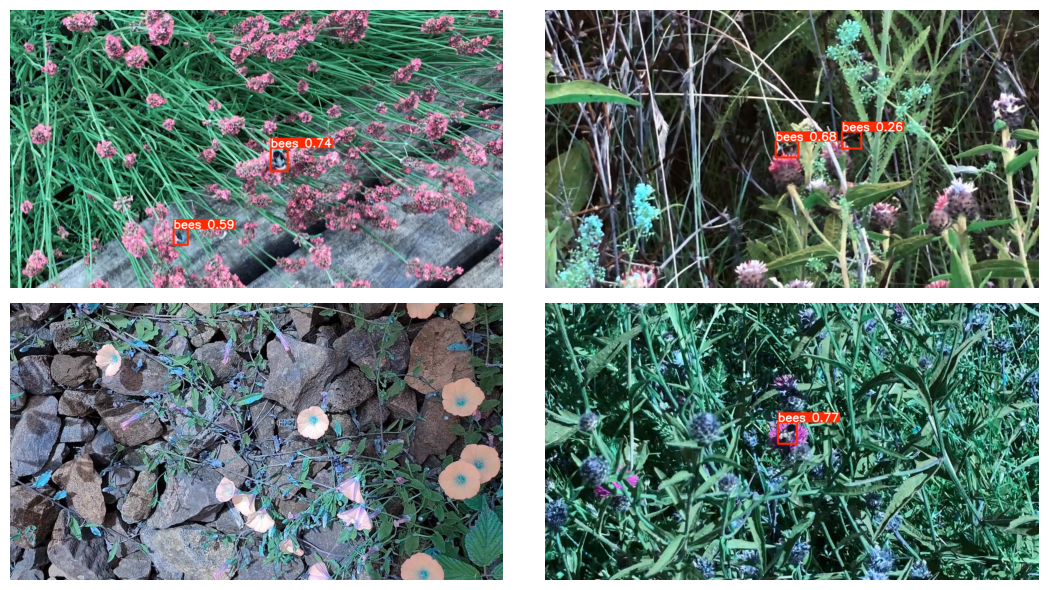

In [26]:
# 定义采样数量
num_samples = 4

# 指定测试图片目录
test_img_dir = 'kaggle/input/test/images'
# 获取测试图片目录下的所有图片文件名
image_files = os.listdir(test_img_dir)
# 随机选择指定数量的图片文件作为测试图片
test_imgs = random.sample(image_files, num_samples)

# 创建一个 2 * 2 的图幅，用于展示 4 个测试图片的预测结果
fig, axes = plt.subplots(2, 2, figsize = (11, 6))

# 遍历每张测试图片
for i in range(num_samples):
    # 获取当前测试图片的文件名
    image = test_imgs[i]
    # 根据索引确定图片在 2 * 2 图幅中的位置
    ax = axes[i // 2, i % 2]
    # 使用模型对当前测试图片进行预测
    result_predict = model.predict(source = os.path.join(test_img_dir, image))
    # 在图幅中相应位置上展示预测结果图片
    ax.imshow(result_predict[0].plot())
    # 关闭图片坐标轴显示
    ax.axis('off')

# 调整图幅布局，确保图片标题和图片本身不重叠
plt.tight_layout()